In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
import scienceplots
import matplotlib.ticker as mticker
import numpy as np


In [2]:
mpl.rcParams.update({
    "font.family": "Cambria",
    "font.size": 11,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

<>:67: SyntaxWarning: invalid escape sequence '\S'
<>:68: SyntaxWarning: invalid escape sequence '\S'
<>:69: SyntaxWarning: invalid escape sequence '\S'
<>:70: SyntaxWarning: invalid escape sequence '\S'
<>:71: SyntaxWarning: invalid escape sequence '\S'
<>:72: SyntaxWarning: invalid escape sequence '\S'
<>:73: SyntaxWarning: invalid escape sequence '\S'
<>:74: SyntaxWarning: invalid escape sequence '\S'
<>:75: SyntaxWarning: invalid escape sequence '\S'
<>:76: SyntaxWarning: invalid escape sequence '\S'
<>:67: SyntaxWarning: invalid escape sequence '\S'
<>:68: SyntaxWarning: invalid escape sequence '\S'
<>:69: SyntaxWarning: invalid escape sequence '\S'
<>:70: SyntaxWarning: invalid escape sequence '\S'
<>:71: SyntaxWarning: invalid escape sequence '\S'
<>:72: SyntaxWarning: invalid escape sequence '\S'
<>:73: SyntaxWarning: invalid escape sequence '\S'
<>:74: SyntaxWarning: invalid escape sequence '\S'
<>:75: SyntaxWarning: invalid escape sequence '\S'
<>:76: SyntaxWarning: invalid e

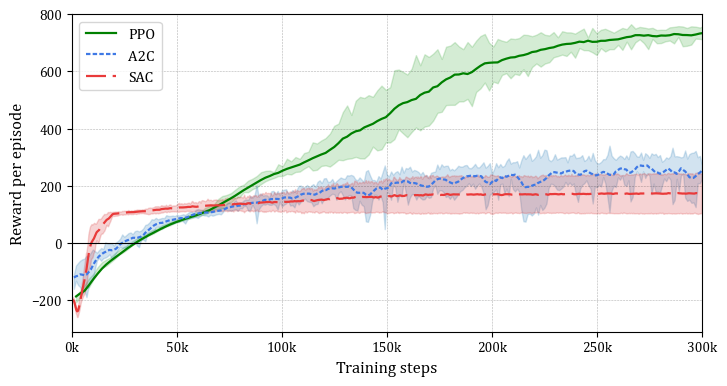

In [3]:
plt.figure(figsize=(7.4, 4.0))
#******************************************************************************************************
df_PPO = pd.read_csv("Data_PPO.csv", header=None, names=["Step", "EpRewMean1", "EpRewMean2", "EpRewMean3", "EpRewMean4", "EpRewMean5"
                                                     , "EpRewMean6", "EpRewMean7", "EpRewMean8", "EpRewMean9", "EpRewMean10"])

reward_cols = ["EpRewMean1", "EpRewMean2", "EpRewMean3", "EpRewMean4", "EpRewMean5", 
               "EpRewMean6", "EpRewMean7", "EpRewMean8", "EpRewMean9", "EpRewMean10"]

smoothed_runs = []

for col in reward_cols:
    #smoothed = df_PPO[col].rolling(1, min_periods=1).mean()
    smoothed = df_PPO[col]
    smoothed_runs.append(smoothed)

smoothed_runs = np.array(smoothed_runs)

df_PPO["smoothed_mean"] = smoothed_runs.mean(axis=0)
df_PPO["smoothed_std"] = smoothed_runs.std(axis=0, ddof=1)

mydata = pd.Series(df_PPO["smoothed_mean"]).rolling(4, min_periods=1,center=True).mean().to_numpy()


plt.plot(df_PPO["Step"], mydata, color="green", linewidth=1.6, label = "PPO")
plt.fill_between(df_PPO["Step"], 
                 df_PPO["smoothed_mean"] - df_PPO["smoothed_std"], 
                 df_PPO["smoothed_mean"] + df_PPO["smoothed_std"], 
                 color="tab:green", alpha=0.2)

# for col in reward_cols:
#     plt.plot(df_PPO["Step"], df_PPO[col],
#              color="tab:green", alpha=0.15, linewidth=1)

#******************************************************************************************************
df_A2C = pd.read_csv("Data_A2C.csv", header=None, names=["Step", "EpRewMean1", "EpRewMean2", "EpRewMean3", "EpRewMean4", "EpRewMean5",
                                                         "EpRewMean6", "EpRewMean7", "EpRewMean8", "EpRewMean9", "EpRewMean10","EpRewMean11"])

reward_A2C_cols = ["EpRewMean1", "EpRewMean2", "EpRewMean3", "EpRewMean4", "EpRewMean5",
                   "EpRewMean6", "EpRewMean8", "EpRewMean10", "EpRewMean11"]

smoothed_runs = []

for col in reward_A2C_cols:
    #smoothed = df_A2C[col].rolling(1, min_periods=1).mean()
    smoothed = df_A2C[col]
    smoothed_runs.append(smoothed)

smoothed_runs = np.array(smoothed_runs)

df_A2C["smoothed_mean"] = smoothed_runs.mean(axis=0)
df_A2C["smoothed_std"] = smoothed_runs.std(axis=0, ddof=1)

mydata2 = pd.Series(df_A2C["smoothed_mean"]).rolling(4, min_periods=1,center=True).mean().to_numpy()

plt.plot(df_A2C["Step"], mydata2, color="#3f79e5", linewidth=1.6, label = "A2C",
         linestyle=":", dashes=(2,1))
plt.fill_between(df_A2C["Step"], 
                 df_A2C["smoothed_mean"] - df_A2C["smoothed_std"], 
                 df_A2C["smoothed_mean"] + df_A2C["smoothed_std"], 
                 color="tab:blue", alpha=0.2)

# for col in reward_A2C_cols:
#     plt.plot(df_A2C["Step"], df_A2C[col],
#              color="tab:blue", alpha=0.15, linewidth=1)

#******************************************************************************************************
df_SAC_1 = pd.read_csv("Data_SAC(D)\SAC(D)_(50-1-2)_(Seed1)_1.csv", header=None, names=["Step", "EpRewMean"])
df_SAC_2 = pd.read_csv("Data_SAC(D)\SAC(D)_(50-1-2)_(Seed2)_1.csv", header=None, names=["Step", "EpRewMean"])
df_SAC_3 = pd.read_csv("Data_SAC(D)\SAC(D)_(50-1-2)_(Seed3)_1.csv", header=None, names=["Step", "EpRewMean"])
df_SAC_4 = pd.read_csv("Data_SAC(D)\SAC(D)_(50-1-2)_(Seed4)_1.csv", header=None, names=["Step", "EpRewMean"])
df_SAC_5 = pd.read_csv("Data_SAC(D)\SAC(D)_(50-1-2)_(Seed5)_1.csv", header=None, names=["Step", "EpRewMean"])
df_SAC_6 = pd.read_csv("Data_SAC(D)\SAC(D)_(50-1-2)_(Seed6)_1.csv", header=None, names=["Step", "EpRewMean"])
df_SAC_7 = pd.read_csv("Data_SAC(D)\SAC(D)_(50-1-2)_(Seed7)_1.csv", header=None, names=["Step", "EpRewMean"])
df_SAC_8 = pd.read_csv("Data_SAC(D)\SAC(D)_(50-1-2)_(Seed8)_1.csv", header=None, names=["Step", "EpRewMean"])
df_SAC_9 = pd.read_csv("Data_SAC(D)\SAC(D)_(50-1-2)_(Seed9)_1.csv", header=None, names=["Step", "EpRewMean"])
df_SAC_10 = pd.read_csv("Data_SAC(D)\SAC(D)_(50-1-2)_(Seed10)_1.csv", header=None, names=["Step", "EpRewMean"])
dfs = [df_SAC_1, df_SAC_2, df_SAC_3, df_SAC_4, df_SAC_5, df_SAC_6, df_SAC_7, df_SAC_8, df_SAC_9, df_SAC_10]

min_step = max(df["Step"].min() for df in dfs)
max_step = min(df["Step"].max() for df in dfs)
common_steps = np.linspace(min_step, max_step, 1000)

all_runs = []

for df in dfs:
    x = df["Step"].values
    y = df["EpRewMean"].values
    y_interp = np.interp(common_steps, x, y)
    all_runs.append(y_interp)

all_runs = np.array(all_runs)

mean = np.mean(all_runs, axis=0)
std = np.std(all_runs, axis=0, ddof=1)

mean2 = pd.Series(mean).rolling(4, min_periods=1,center=True).mean().to_numpy()

plt.plot(common_steps, mean2, color="#e93a3a", linewidth=1.6, label = "SAC",
         linestyle="--", dashes=(9,3))
plt.fill_between(common_steps, 
                 mean - std, 
                 mean + std, 
                 color="tab:red", alpha=0.2)

# for df in dfs:
#     plt.plot(df["Step"], df["EpRewMean"],
#              color="tab:red", alpha=0.15, linewidth=1)

#******************************************************************************************************

plt.xlabel("Training steps", fontsize=12)
plt.ylabel("Reward per episode", fontsize=12)
plt.grid(True, color='black', linestyle='--', linewidth=0.4, alpha=0.3)

#plt.title("Average over 10 different seeds", pad=8, fontsize=11)


# --- Set x‑axis minimum at 0 ---
plt.xlim(left=0, right=300000)

# --- Set x‑axis minimum at 0 ---
plt.ylim(top=800)

# → horizontal line at y = 0
plt.axhline(y=0, color='black', linewidth=0.8)

# --- Format x‑axis ticks as 50k, 100k, 150k, etc. ---
plt.gca().xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x/1000)}k"))

plt.tight_layout()
plt.legend()
plt.savefig("Fig8_new_Springer.png", dpi=600, bbox_inches='tight')
plt.show()